# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/deepikachebrolu/flyrank-ml/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.


**Lane:** CTR / Engagement Opportunity Scoring

This notebook consolidates the weekly work into a reproducible research summary. It loads existing validation and action-playbook artifacts, creates paper-ready aggregate outputs, and records limitations. It does not invent results when an expected artifact is missing.

**Public-safety rule:** Do not publish raw datasets, row-level queues, client identifiers, domains, private queries, or credentials. Publish aggregate results and carefully reviewed recommendations only.


## 1. Question


**Research question:** Can observable content and search-performance signals support a transparent, human-reviewed prioritization system for identifying pages that deserve further investigation?

**Decision supported:** Help a content or SEO reviewer decide which pages to inspect first—not automatically decide what to rewrite, predict guaranteed CTR uplift, or claim causal effects.

**Project lane:** CTR / Engagement Opportunity Scoring.

The Week 6 evaluation recorded here tests CTR prediction. The action playbook is a separate rule-based decision-support layer; it should not be described as a validated predictive model.

In [10]:
from pathlib import Path
import json
import math
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


current = Path.cwd().resolve()
ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "work" / "outputs").exists()
     and (p / "work" / "notebooks").exists()),
    None,
)
if ROOT is None:
    ROOT = next(
        (p for p in [current, *current.parents]
         if (p / "outputs").exists()
         and (p / "notebooks").exists()),
        None,
    )
    if ROOT is not None and ROOT.name == "work":
        ROOT = ROOT.parent

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the flyrank-ml repository. "
        "Run this notebook from the repository or work/notebooks folder."
    )

OUTPUT_DIR = ROOT / "work" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

METRICS_PATH = OUTPUT_DIR / "w06_validation_metrics.json"
QUEUE_PATH = OUTPUT_DIR / "w07_ranked_action_queue.csv"
PLAYBOOK_SUMMARY_PATH = OUTPUT_DIR / "w07_action_playbook_summary.json"

print("Repository root:", ROOT)
print("Outputs directory:", OUTPUT_DIR)
print("Validation metrics present:", METRICS_PATH.exists())
print("Ranked action queue present:", QUEUE_PATH.exists())
print("Playbook summary present:", PLAYBOOK_SUMMARY_PATH.exists())


Repository root: C:\Users\Divya\Documents\flyrank-ml
Outputs directory: C:\Users\Divya\Documents\flyrank-ml\work\outputs
Validation metrics present: True
Ranked action queue present: True
Playbook summary present: True


## 2. Data

The analysis uses the anonymized content-refresh dataset and the weekly artifacts generated from it in this repository. The exact release identifier, source tables, and date windows must be copied from the data contract or dataset manifest; they are not inferred from filenames.

### Data handling and exclusions

- Client and content identifiers are not model features. They may exist in local analysis artifacts for joins or audit purposes.
- Target-derived trend fields and the target itself are excluded from predictive features.
- Click measures that overlap with the target are excluded from the documented baseline feature vector.
- Historical impressions, clicks, sessions, engagement, and position measures require timestamp/window verification before any operational prediction.
- Public outputs should contain aggregate metrics and sanitized recommendations, not row-level records or identifiers.

**Data-source note:** Confirm the precise release name and observation windows in `w02_ml_task_framing.ipynb` / `w03_data_contract.ipynb` before publishing. Do not claim a date range that those sources do not establish.


In [11]:

metrics = None
playbook_summary = None

if METRICS_PATH.exists():
    with open(METRICS_PATH, "r", encoding="utf-8") as f:
        metrics = json.load(f)
    print("Loaded validation metrics.")
else:
    print("WARNING: validation metrics JSON is missing; results cannot be reported yet.")

if PLAYBOOK_SUMMARY_PATH.exists():
    with open(PLAYBOOK_SUMMARY_PATH, "r", encoding="utf-8") as f:
        playbook_summary = json.load(f)
    print("Loaded playbook summary.")
else:
    print("WARNING: playbook summary JSON is missing.")

if metrics:
    print("\nValidation artifact keys:", list(metrics.keys()))
    print("Split strategy:", metrics.get("split_strategy", "Not recorded"))
    print("Train/test rows:", metrics.get("train_rows"), "/", metrics.get("test_rows"))
    print("Train/test clients:", metrics.get("train_clients"), "/", metrics.get("test_clients"))
    print("Client overlap:", metrics.get("client_overlap"))
    print("Target:", metrics.get("target"))
    print("Feature count:", len(metrics.get("features", [])))


Loaded validation metrics.
Loaded playbook summary.

Validation artifact keys: ['dataset', 'target', 'group_column', 'features', 'random_seed', 'split_strategy', 'train_rows', 'test_rows', 'train_clients', 'test_clients', 'client_overlap', 'baseline', 'random_forest']
Split strategy: GroupShuffleSplit by client
Train/test rows: 23837 / 6163
Train/test clients: 25 / 7
Client overlap: 0
Target: ctr
Feature count: 36


## 3. Methodology

### Target and feature vector

The recorded Week 6 task predicts the observed `ctr` field. CTR is an observed metric, not a label for future improvement after an editorial action.

The feature set is read from the saved validation artifact. The documented exclusions include identifiers (`client_id`, `content_id`), the target (`ctr`), label/trend-derived fields (`trend_direction`, `trend_pct`, `is_declining_label`), a generic target alias, and selected outcome-related/provider fields.

### Baseline and model

The recorded validation compares a median baseline with a Random Forest on the same client-grouped holdout split. Preprocessing and feature definitions should match the saved artifact and the Week 6 notebook.

### Validation and leakage checks

Client-grouped splitting prevents the same client from appearing in both train and test partitions in the recorded evaluation. It does not, by itself, prove that every feature was available before the prediction time. Temporal availability still needs to be checked against the data contract.

In [12]:

if metrics:
    assert metrics.get("client_overlap", 0) == 0, (
        "Recorded validation reports client overlap; investigate before publishing."
    )

    forbidden = {
        "client_id", "content_id", "ctr", "target",
        "clicks_90d", "trend_direction", "trend_pct",
        "is_declining_label", "provider_used", "model_used",
    }
    included_forbidden = sorted(set(metrics.get("features", [])) & forbidden)
    print("Forbidden fields in saved feature list:", included_forbidden)
    assert not included_forbidden, (
        "Saved feature list contains a known excluded field."
    )

    print("Split and known-field leakage checks passed.")
else:
    print("Checks skipped because the validation metrics artifact is missing.")


Forbidden fields in saved feature list: []
Split and known-field leakage checks passed.


## 4. Results (vs baseline)

The table below is built from the actual `w06_validation_metrics.json` artifact. Do not replace missing values with remembered or estimated numbers.

MAE and RMSE are error measures where lower is better. R² can be negative; a negative value indicates performance worse than the test-set mean predictor under the standard R² definition.

The baseline and model must refer to the same test set for this comparison to be valid.

,Metric,Median baseline,Random Forest
0,MAE,0.292440,0.366229
1,RMSE,1.103612,1.249693
2,R²,-0.037594,-0.330458


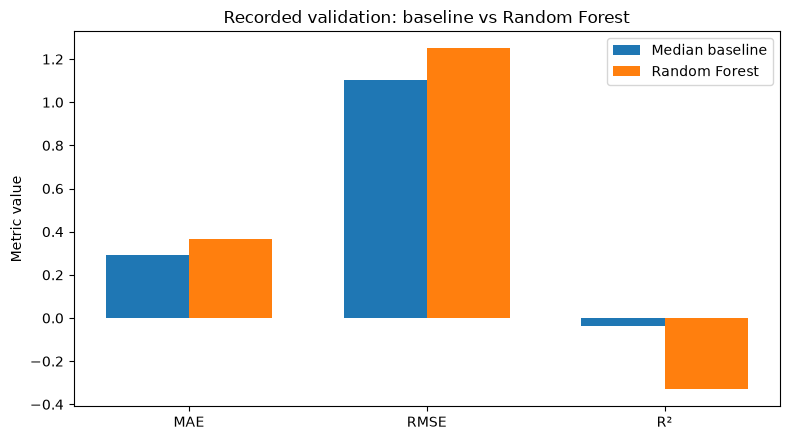


Interpretation from saved values:
Random Forest MAE better than baseline: False
Random Forest RMSE better than baseline: False
Random Forest R² negative: True


In [13]:
def find_metric_dict(obj, candidates):
    for key in candidates:
        value = obj.get(key) if isinstance(obj, dict) else None
        if isinstance(value, dict) and any(k in value for k in ["MAE", "RMSE", "R2", "R²"]):
            return value
    return {}

results_table = None
if metrics:
    baseline = find_metric_dict(metrics, ["baseline", "median_baseline"])
    model = find_metric_dict(metrics, ["random_forest", "model", "rf"])

    if baseline and model:
        def metric_value(d, *keys):
            for key in keys:
                if key in d:
                    return d[key]
            return np.nan

        results_table = pd.DataFrame({
            "Metric": ["MAE", "RMSE", "R²"],
            "Median baseline": [
                metric_value(baseline, "MAE"),
                metric_value(baseline, "RMSE"),
                metric_value(baseline, "R2", "R²"),
            ],
            "Random Forest": [
                metric_value(model, "MAE"),
                metric_value(model, "RMSE"),
                metric_value(model, "R2", "R²"),
            ],
        })
        display(results_table)
        results_table.to_csv(OUTPUT_DIR / "capstone_model_comparison.csv", index=False)

        # Figure uses the actual recorded values.
        fig, ax = plt.subplots(figsize=(8, 4.5))
        x = np.arange(len(results_table))
        width = 0.35
        ax.bar(x - width/2, results_table["Median baseline"], width, label="Median baseline")
        ax.bar(x + width/2, results_table["Random Forest"], width, label="Random Forest")
        ax.set_xticks(x)
        ax.set_xticklabels(results_table["Metric"])
        ax.set_title("Recorded validation: baseline vs Random Forest")
        ax.set_ylabel("Metric value")
        ax.legend()
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "capstone_model_comparison.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        mae_b = metric_value(baseline, "MAE")
        mae_m = metric_value(model, "MAE")
        rmse_b = metric_value(baseline, "RMSE")
        rmse_m = metric_value(model, "RMSE")
        r2_b = metric_value(baseline, "R2", "R²")
        r2_m = metric_value(model, "R2", "R²")

        print("\nInterpretation from saved values:")
        print("Random Forest MAE better than baseline:", bool(mae_m < mae_b))
        print("Random Forest RMSE better than baseline:", bool(rmse_m < rmse_b))
        print("Random Forest R² negative:", bool(r2_m < 0))
    else:
        print("Could not find baseline/model metric dictionaries in the expected schema.")
        print("Inspect the JSON keys and update this cell to match the artifact.")
else:
    print("No results table generated because the metrics artifact is missing.")


## 5. Limitations

1. The dataset is observational; it does not establish that a content refresh causes improved search performance.
2. The recorded Random Forest evaluation did not establish reliable predictive superiority over the median baseline.
3. CTR is affected by search intent, query mix, search-result layout, position, brand recognition, and other factors.
4. Average position and page-level aggregates can hide query, device, location, and time differences.
5. The exact temporal availability of each feature must be verified. A client-grouped split does not solve temporal leakage automatically.
6. Rule-based priority scores are heuristics, not probabilities, predicted uplift, or financial ROI.
7. Relative thresholds depend on the current dataset distribution.
8. The action queue is for human review. No content should be automatically rewritten, published, deleted, or refreshed based only on these outputs.

Claims in the paper should use careful language such as *observed*, *associated with*, *directional*, and *decision-support*. Avoid claims that prove Google's ranking algorithm or causal refresh impact.


In [14]:
limitations = [
    "Observational data does not establish causal refresh impact.",
    "The recorded model evaluation does not establish predictive superiority over the baseline.",
    "CTR depends on query mix, intent, position, and search-result context.",
    "Temporal availability of every feature must be verified.",
    "Rule-based priority scores are heuristics, not probabilities or expected uplift.",
    "Human review is required; content changes are not automated.",
]
for i, item in enumerate(limitations, start=1):
    print(f"{i}. {item}")


1. Observational data does not establish causal refresh impact.
2. The recorded model evaluation does not establish predictive superiority over the baseline.
3. CTR depends on query mix, intent, position, and search-result context.
4. Temporal availability of every feature must be verified.
5. Rule-based priority scores are heuristics, not probabilities or expected uplift.
6. Human review is required; content changes are not automated.


## 6. Ranked recommendations

The action playbook converts observable signals into a review queue. It does not use the Random Forest prediction as a ranking score.

Recommended archetypes include:
- **CTR review:** relatively high impressions with relatively low CTR; inspect query intent, title/snippet, and search-result context.
- **Freshness review:** inspect whether older content is factually outdated; age alone is not proof of decay.
- **Ranking review:** investigate visible pages with average position between 4 and 20.
- **Engagement review:** inspect engagement definitions and page relevance for records with low relative engagement.
- **Monitor:** no current rule matched, or evidence is insufficient for a specific action.

A high priority means “review earlier,” not “implement immediately.” The reviewer must validate metrics, business context, risk, and effort before deciding what to do.


In [15]:

if QUEUE_PATH.exists():
    queue = pd.read_csv(QUEUE_PATH)
    print("Queue rows loaded:", len(queue))
    print("Queue columns:", queue.columns.tolist())

    if "action_archetype" not in queue.columns or "reason_code" not in queue.columns:
        raise ValueError("Queue is missing action_archetype or reason_code.")

    public_summary = (
        queue.groupby(["action_archetype", "reason_code"], dropna=False)
        .size()
        .reset_index(name="record_count")
        .sort_values(["record_count", "action_archetype"], ascending=[False, True])
    )

    display(public_summary)

    public_summary_path = OUTPUT_DIR / "capstone_public_action_summary.csv"
    public_summary.to_csv(public_summary_path, index=False)

    print("Public aggregate summary saved to:", public_summary_path)
else:
    queue = None
    public_summary = None
    print("WARNING: ranked queue CSV is missing or ignored by Git.")
    print("Run the Week 7 action-playbook notebook first.")


Queue rows loaded: 30000
Queue columns: ['priority_rank', 'priority_score', 'content_id', 'client_id', 'action_archetype', 'reason_code', 'recommended_action', 'review_reason', 'impressions_90d', 'ctr', 'avg_position', 'content_age_days', 'days_since_last_update', 'sessions_90d', 'engagement_rate']


,action_archetype,reason_code,record_count
1,ENGAGEMENT_REVIEW,LOW_RELATIVE_ENGAGEMENT,19984
5,RANKING_REVIEW,VISIBLE_POSITION_4_TO_20,5012
4,MONITOR,NO_PRIORITY_RULE_MATCH,4842
0,CTR_REVIEW,HIGH_IMPRESSIONS_LOW_CTR,146
2,FRESHNESS_REVIEW,STALE_CONTENT_REVIEW,8
3,FRESHNESS_REVIEW,STALE_HIGH_VISIBILITY,8


Public aggregate summary saved to: C:\Users\Divya\Documents\flyrank-ml\work\outputs\capstone_public_action_summary.csv


## 7. Artifacts the paper embeds

This section creates paper-ready files from the actual artifacts available in the repository.

Generated artifacts:
- `capstone_model_comparison.csv` — recorded baseline/model metrics.
- `capstone_model_comparison.png` — metric comparison chart.
- `capstone_public_action_summary.csv` — aggregate action counts without row-level identifiers.
- `capstone_paper_facts.json` — a compact summary for building the deployed paper.

The paper must also include an abstract, introduction/problem statement, data, methodology, results, limitations, ranked recommendations, reproducibility, and acknowledgments/data credit. Confirm the release details against your data-contract notebook before publication.

In [16]:

paper_facts = {
    "title": "CTR & Engagement Opportunity Scoring: A Human-Reviewed Content Prioritization Framework",
    "research_question": (
        "Can observable content and search-performance signals support "
        "a transparent, human-reviewed prioritization system?"
    ),
    "lane": "CTR / Engagement Opportunity Scoring",
    "validation_artifact_available": bool(metrics),
    "playbook_summary_available": bool(playbook_summary),
    "queue_available": bool(QUEUE_PATH.exists()),
    "validation": {},
    "playbook_action_counts": (
        playbook_summary.get("action_counts", {})
        if isinstance(playbook_summary, dict) else {}
    ),
    "public_artifacts": [
        "work/outputs/capstone_model_comparison.csv",
        "work/outputs/capstone_model_comparison.png",
        "work/outputs/capstone_public_action_summary.csv",
    ],
    "required_data_credit": "Built on the FlyRank ML Internship dataset.",
    "data_credit_url": "https://flyrank.ai",
    "publication_warning": (
        "Verify dataset release/date windows from the data contract; "
        "do not publish row-level queues, identifiers, private URLs, or queries."
    ),
}

if metrics:
    paper_facts["validation"] = {
        "target": metrics.get("target"),
        "split_strategy": metrics.get("split_strategy"),
        "train_rows": metrics.get("train_rows"),
        "test_rows": metrics.get("test_rows"),
        "train_clients": metrics.get("train_clients"),
        "test_clients": metrics.get("test_clients"),
        "client_overlap": metrics.get("client_overlap"),
        "baseline": metrics.get("baseline", {}),
        "random_forest": metrics.get("random_forest", {}),
    }

facts_path = OUTPUT_DIR / "capstone_paper_facts.json"
with open(facts_path, "w", encoding="utf-8") as f:
    json.dump(paper_facts, f, indent=2)

print("Paper facts saved to:", facts_path)
print(json.dumps(paper_facts, indent=2))


Paper facts saved to: C:\Users\Divya\Documents\flyrank-ml\work\outputs\capstone_paper_facts.json
{
  "title": "CTR & Engagement Opportunity Scoring: A Human-Reviewed Content Prioritization Framework",
  "research_question": "Can observable content and search-performance signals support a transparent, human-reviewed prioritization system?",
  "lane": "CTR / Engagement Opportunity Scoring",
  "validation_artifact_available": true,
  "playbook_summary_available": true,
  "queue_available": true,
  "validation": {
    "target": "ctr",
    "split_strategy": "GroupShuffleSplit by client",
    "train_rows": 23837,
    "test_rows": 6163,
    "train_clients": 25,
    "test_clients": 7,
    "client_overlap": 0,
    "baseline": {
      "MAE": 0.2924403699496998,
      "RMSE": 1.1036120022751637,
      "R2": -0.0375936856891399
    },
    "random_forest": {
      "MAE": 0.3662292207172639,
      "RMSE": 1.2496930901955035,
      "R2": -0.330458177694434
    }
  },
  "playbook_action_counts": {
   

## 8. Reproducibility

Repository: https://github.com/deepikachebrolu/flyrank-ml

Relevant notebooks:
- `work/notebooks/w02_ml_task_framing.ipynb`
- `work/notebooks/w03_data_contract.ipynb`
- `work/notebooks/w03_feature_leakage_check.ipynb`
- `work/notebooks/w04_baseline_score.ipynb`
- `work/notebooks/w05_model.ipynb`
- `work/notebooks/w06_validation_audit.ipynb`
- `work/notebooks/w07_action_playbook.ipynb`
- `work/notebooks/capstone.ipynb`

For reproducibility, run the weekly notebooks in order, confirm their outputs correspond to the same data snapshot, then run this capstone notebook. The deployed paper URL must be recorded as a single line in `submission/paper_url.txt` after deployment has been verified.


## 9. Five-sentence abstract draft

This capstone examines whether observable content and search-performance signals can support a transparent, human-reviewed content prioritization workflow. It evaluates CTR prediction using a median baseline and a Random Forest under a client-grouped holdout design, with known target-derived and identifier fields excluded from the feature set. In the recorded Week 6 evaluation, the Random Forest did not outperform the median baseline on the reported error and fit metrics. Because predictive performance was not established, the recommendations use transparent rules to flag pages for investigation rather than treating model predictions as expected uplift. The resulting playbook is a decision-support prototype, and its recommendations require human review and further validation before operational use.


## 10. ML-12 closing materials

### Five-minute demo outline
1. **0:00–0:40 — Problem:** Explain why content teams need a consistent way to decide which pages to investigate.
2. **0:40–1:20 — Data and safety:** Show the anonymized data approach, target definition, and excluded leakage fields.
3. **1:20–2:10 — Validation:** Show the same-split baseline-versus-Random-Forest metrics and explain the model's limitations.
4. **2:10–3:40 — Action playbook:** Show action archetypes, reason codes, and the aggregate action-count chart.
5. **3:40–4:30 — Human review:** Explain what the queue can and cannot recommend and what remains manual.
6. **4:30–5:00 — Reproducibility:** Show the repository, notebook, and deployed paper.

### Social-post cut
I built a search-content prioritization capstone using anonymized content and performance data. Instead of overstating a model that did not beat its baseline, I turned the findings into an explainable, rule-based review queue with reason codes and human-review safeguards. The project emphasizes honest validation, leakage checks, reproducibility, and careful interpretation of observational data.

### Three-sentence employer-facing summary
I built a reproducible machine-learning research workflow to evaluate CTR prediction and translate observed content signals into a human-reviewed prioritization playbook. I used client-grouped validation, a baseline comparison, feature exclusions, and leakage checks, and documented where the model did not demonstrate an improvement. The final deliverable combines measurable evaluation results with explainable recommendations, privacy-conscious reporting, and a deployment-ready research-paper structure.


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
